# American option pricer : summary

Longstaff-Schwartz Monte Carlo pricer for American options under Black-Scholes with continuous dividend yield. Random numbers come from a home-made generator (LCG + Box-Muller).
This notebook replays the key results of the project.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt

from src.rng import LCG
from src.european import bs_price, mc_european
from src.lsm import lsm_price
from src.binomial import crr_price
from src.analysis import compare_american_european, convergence_study

S0, K, r, q, sigma, T = 100.0, 100.0, 0.05, 0.02, 0.20, 1.0
n_steps, n_paths = 50, 20_000

## 1. Random number generator

Standard normals from a linear congruential generator and the Box-Muller transform.

In [2]:
from scipy.stats import kstest

z = LCG(seed=42).normal(100_000)
stat, pvalue = kstest(z[:10_000], "norm")

print(f"Mean {z.mean():+.4f} | Std {z.std():.4f} | KS p-value (10,000 samples) {pvalue:.3f}")

Mean +0.0016 | Std 1.0013 | KS p-value (10,000 samples) 0.185


## 2. European options: Monte Carlo vs closed form

In [3]:
for opt in ["call", "put"]:
    mc = mc_european(S0, K, r, q, sigma, T, 100_000, LCG(seed=42), opt)
    bsm = bs_price(S0, K, r, q, sigma, T, opt)
    inside = mc["ci_low"] <= bsm <= mc["ci_high"]
    print(f"{opt:4s} | MC {mc['price']:.4f} (se {mc['std_error']:.4f}) | BSM {bsm:.4f} | BSM inside CI: {inside}")

call | MC 9.2590 (se 0.0438) | BSM 9.2270 | BSM inside CI: True
put  | MC 6.3256 (se 0.0290) | BSM 6.3301 | BSM inside CI: True


## 3. American options: LSM vs binomial trees

The LSM pricer has 50 exercise dates (Bermudan), so the exact benchmark is a bermudan tree with the same 50 dates.

In [4]:
lsm_res = {}
for opt in ["call", "put"]:
    lsm_res[opt] = lsm_price(S0, K, r, q, sigma, T, n_steps, n_paths, LCG(seed=42), opt, degree=2, itm_only=True)
    eur = bs_price(S0, K, r, q, sigma, T, opt)
    berm = crr_price(S0, K, r, q, sigma, T, 1000, opt, american=True, exercise_every=20)
    amer = crr_price(S0, K, r, q, sigma, T, 2000, opt, american=True)
    res = lsm_res[opt]
    print(f"{opt:4s} | European {eur:.4f} | Bermudan tree {berm:.4f} | American tree {amer:.4f} " f"| LSM {res['price']:.4f} (se {res['std_error']:.4f})")

berm_put = crr_price(S0, K, r, q, sigma, T, 1000, "put", american=True, exercise_every=20)
eur_put = bs_price(S0, K, r, q, sigma, T, "put")

call | European 9.2270 | Bermudan tree 9.2251 | American tree 9.2260 | LSM 9.1861 (se 0.0913)
put  | European 6.3301 | Bermudan tree 6.6517 | American tree 6.6602 | LSM 6.6242 (se 0.0550)


## 4. Early exercise premium of the put across strikes

In [5]:
strikes = [80, 90, 100, 110, 120]
df = compare_american_european(S0, strikes, r, q, sigma, T, n_steps, n_paths, options=("put",))
print(df[["strike", "european", "american", "std_error", "premium"]].round(4).to_string(index=False))

 strike  european  american  std_error  premium
     80    0.8426    0.8836     0.0195   0.0410
     90    2.7145    2.8063     0.0358   0.0918
    100    6.3301    6.6242     0.0550   0.2941
    110   11.8040   12.5893     0.0656   0.7854
    120   18.8394   20.5748     0.0640   1.7354


## 5. Regression degree and path selection

In [6]:
degrees = [1, 2, 3, 4]
deg_prices = {True: [], False: []}
for itm_only in [True, False]:
    for d in degrees:
        out = lsm_price(S0, K, r, q, sigma, T, n_steps, 10_000, LCG(seed=42), "put", degree=d, itm_only=itm_only)
        deg_prices[itm_only].append(out["price"])

print("degree | ITM only | All paths")
for i, d in enumerate(degrees):
    print(f"  {d}    |  {deg_prices[True][i]:.4f}  |  {deg_prices[False][i]:.4f}")

degree | ITM only | All paths
  1    |  6.5946  |  6.3660
  2    |  6.6878  |  6.6575
  3    |  6.7000  |  6.6439
  4    |  6.7091  |  6.6860


## 6. Confidence Interval vs number of paths

In [7]:
n_grid = [1_000, 2_500, 5_000, 10_000, 20_000]
study = convergence_study(S0, K, r, q, sigma, T, n_steps, n_grid, n_rep=1)

slope, _ = np.polyfit(np.log(study["N"]), np.log(study["std_error"]), 1)
print(study[["N", "price", "std_error"]].round(4).to_string(index=False))
print(f"\nSlope of log(std_error) vs log(N): {slope:.3f} (theory: -0.5)")

    N  price  std_error
 1000 7.2562     0.2590
 2500 6.5875     0.1523
 5000 6.6704     0.1078
10000 6.5348     0.0768
20000 6.6226     0.0548

Slope of log(std_error) vs log(N): -0.515 (theory: -0.5)


## 7. Summary figure

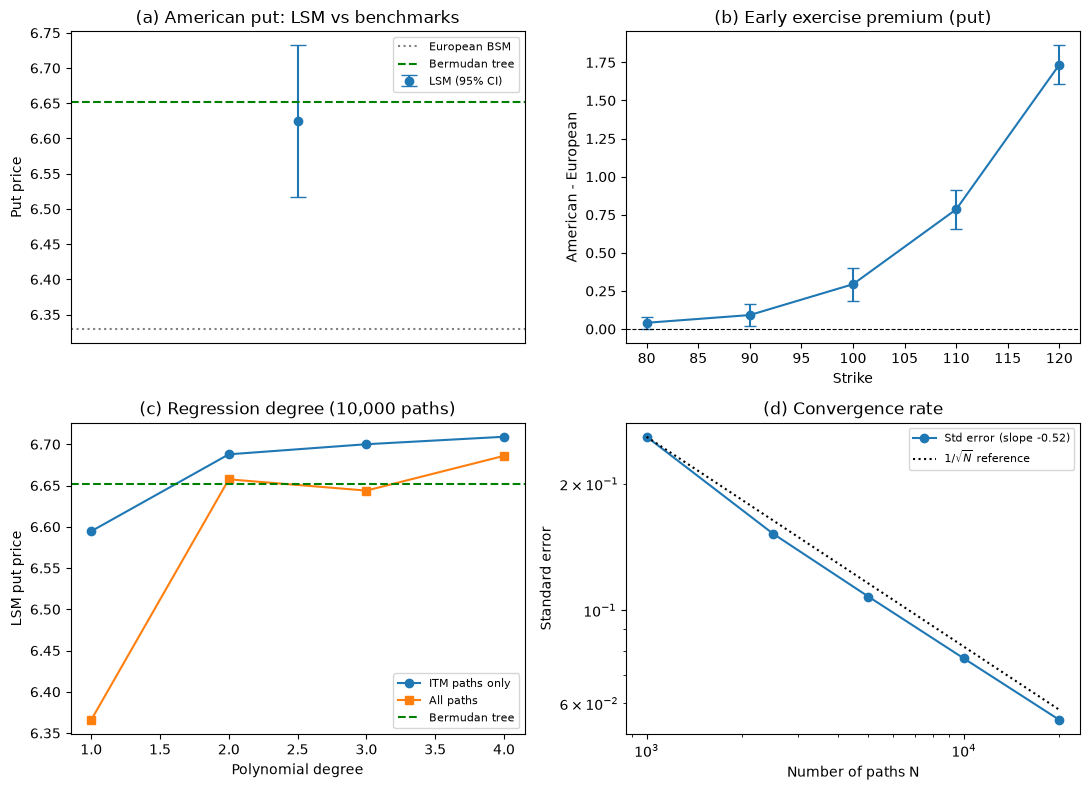

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(11, 8))

# (a) American put: LSM vs benchmarks
res = lsm_res["put"]
ax[0, 0].errorbar([0], [res["price"]], yerr=[1.96 * res["std_error"]], fmt="o", capsize=6, label="LSM (95% CI)")
ax[0, 0].axhline(eur_put, color="gray", linestyle=":", label="European BSM")
ax[0, 0].axhline(berm_put, color="green", linestyle="--", label="Bermudan tree")
ax[0, 0].set_xticks([])
ax[0, 0].set_ylabel("Put price")
ax[0, 0].set_title("(a) American put: LSM vs benchmarks")
ax[0, 0].legend(fontsize=8)

# (b) Early exercise premium vs strike
ax[0, 1].errorbar(df["strike"], df["premium"], yerr=1.96 * df["std_error"], fmt="o-", capsize=4)
ax[0, 1].axhline(0, color="black", lw=0.8, linestyle="--")
ax[0, 1].set_xlabel("Strike")
ax[0, 1].set_ylabel("American - European")
ax[0, 1].set_title("(b) Early exercise premium (put)")

# (c) Regression degree
ax[1, 0].plot(degrees, deg_prices[True], "o-", label="ITM paths only")
ax[1, 0].plot(degrees, deg_prices[False], "s-", label="All paths")
ax[1, 0].axhline(berm_put, color="green", linestyle="--", label="Bermudan tree")
ax[1, 0].set_xlabel("Polynomial degree")
ax[1, 0].set_ylabel("LSM put price")
ax[1, 0].set_title("(c) Regression degree (10,000 paths)")
ax[1, 0].legend(fontsize=8)

# (d) Convergence of the standard error
ax[1, 1].loglog(study["N"], study["std_error"], "o-", label=f"Std error (slope {slope:.2f})")
ax[1, 1].loglog(study["N"], study["std_error"].iloc[0] * np.sqrt(study["N"].iloc[0] / study["N"]), "k:", label=r"$1/\sqrt{N}$ reference")
ax[1, 1].set_xlabel("Number of paths N")
ax[1, 1].set_ylabel("Standard error")
ax[1, 1].set_title("(d) Convergence rate")
ax[1, 1].legend(fontsize=8)

plt.tight_layout()
plt.savefig("../figures/summary.png", dpi=150)
plt.show()